<a href="https://colab.research.google.com/github/Saranya782/ICTDSA/blob/main/Case_Study_On_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Load dataset
df = pd.read_csv('car_age_price.csv')
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 112 rows, 2 columns


,Year,Price
0,2018,465000
1,2019,755000
2,2019,700000
3,2018,465000
4,2018,465000


In [8]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Year    112 non-null    int64
 1   Price   112 non-null    int64
dtypes: int64(2)
memory usage: 1.9 KB


,Year,Price
count,112.000000,112.000000
mean,2016.669643,483866.044643
std,1.629616,91217.450533
min,2013.000000,300000.000000
25%,2015.000000,423750.000000
50%,2017.000000,500000.000000
75%,2017.000000,550000.000000
max,2020.000000,755000.000000


Correlation Matrix:
           Year     Price
Year   1.000000  0.776302
Price  0.776302  1.000000


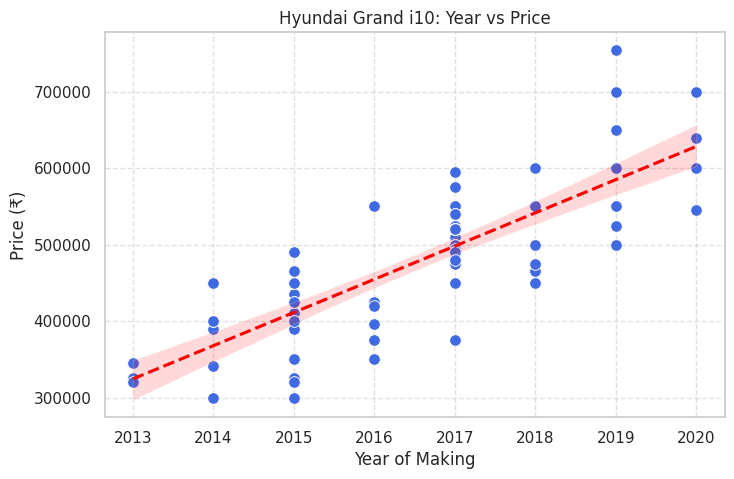

In [9]:
print("Correlation Matrix:")
print(df.corr())

plt.figure(figsize=(8, 5))
sns.scatterplot(x='Year', y='Price', data=df, color='royalblue', s=70)
sns.regplot(x='Year', y='Price', data=df, scatter=False, color='red', line_kws={'linestyle':'--'})
plt.title('Hyundai Grand i10: Year vs Price')
plt.xlabel('Year of Making')
plt.ylabel('Price (₹)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [10]:
X = df[['Year']]
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Train samples: 89, Test samples: 23


In [11]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print(f"Slope (Coefficient): {lr_model.coef_[0]:.2f}")
print(f"Intercept:           {lr_model.intercept_:.2f}")
print(f"Equation:            Price = {lr_model.coef_[0]:.2f} * Year + ({lr_model.intercept_:.2f})")
print(f"MAE:                 ₹{mae_lr:,.2f}")
print(f"RMSE:                ₹{rmse_lr:,.2f}")
print(f"R² Score:            {r2_lr:.4f}")

Slope (Coefficient): 47608.57
Intercept:           -95520922.49
Equation:            Price = 47608.57 * Year + (-95520922.49)
MAE:                 ₹53,534.78
RMSE:                ₹65,779.22
R² Score:            0.3676


In [12]:
lasso_model = Lasso(alpha=1.0, random_state=42)
lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)

mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print(f"Slope (Coefficient): {lasso_model.coef_[0]:.2f}")
print(f"Intercept:           {lasso_model.intercept_:.2f}")
print(f"MAE:                 ₹{mae_lasso:,.2f}")
print(f"RMSE:                ₹{rmse_lasso:,.2f}")
print(f"R² Score:            {r2_lasso:.4f}")

Slope (Coefficient): 47608.16
Intercept:           -95520091.25
MAE:                 ₹53,534.33
RMSE:                ₹65,778.87
R² Score:            0.3676


In [13]:
year_2022 = pd.DataFrame({'Year': [2022]})

pred_lr_2022 = lr_model.predict(year_2022)[0]
pred_lasso_2022 = lasso_model.predict(year_2022)[0]

print(f"Predicted 2022 Price (Linear Regression): ₹{pred_lr_2022:,.2f}")
print(f"Predicted 2022 Price (Lasso Regression):  ₹{pred_lasso_2022:,.2f}")

Predicted 2022 Price (Linear Regression): ₹743,601.62
Predicted 2022 Price (Lasso Regression):  ₹743,599.37


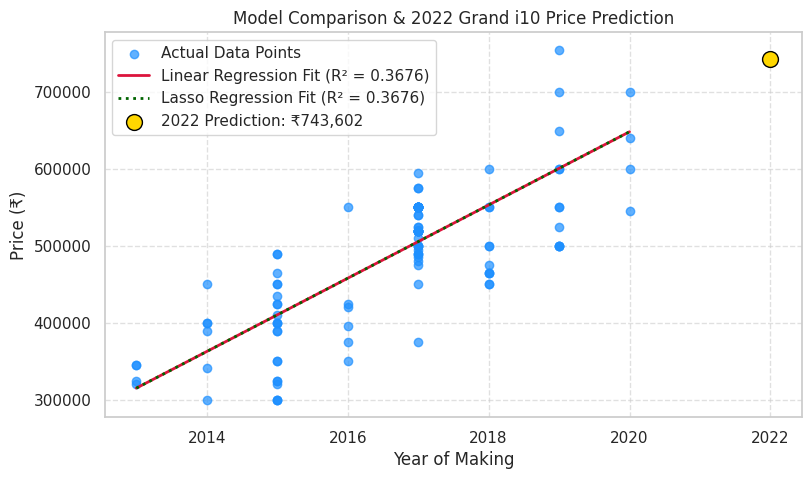

In [14]:
X_test_sorted = X_test.sort_values(by='Year')

plt.figure(figsize=(9, 5))
plt.scatter(X, y, color='dodgerblue', alpha=0.7, label='Actual Data Points')
plt.plot(X_test_sorted['Year'], lr_model.predict(X_test_sorted), color='crimson', lw=2, label=f'Linear Regression Fit (R² = {r2_lr:.4f})')
plt.plot(X_test_sorted['Year'], lasso_model.predict(X_test_sorted), color='darkgreen', lw=2, linestyle=':', label=f'Lasso Regression Fit (R² = {r2_lasso:.4f})')
plt.scatter([2022], [pred_lr_2022], color='gold', edgecolor='black', s=130, zorder=5, label=f'2022 Prediction: ₹{pred_lr_2022:,.0f}')

plt.title('Model Comparison & 2022 Grand i10 Price Prediction')
plt.xlabel('Year of Making')
plt.ylabel('Price (₹)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()